# Visual Experiment Report

Notebook ini menyajikan hasil eksperimen klasifikasi penyakit daun padi dengan pendekatan _storytelling with data_. Fokus visualisasi bukan hanya menampilkan angka, tetapi membantu pembaca memahami pesan utama penelitian.

**Pertanyaan utama:** model mana yang lebih baik untuk klasifikasi tujuh kondisi daun padi, CNN Kustom atau MobileNetV2?

**Pesan utama:** MobileNetV2 memberikan performa lebih baik dibanding CNN Kustom berdasarkan accuracy dan F1-score macro, tetapi CNN Kustom tetap relevan sebagai baseline model yang dilatih dari awal.

Prinsip visual yang digunakan:

1. Setiap grafik menjawab satu pertanyaan.
2. Judul grafik menyampaikan insight, bukan sekadar nama metrik.
3. MobileNetV2 diberi warna highlight, sedangkan CNN Kustom dibuat abu-abu sebagai pembanding.
4. Angka dibulatkan agar mudah dibaca.
5. Setiap visual diikuti interpretasi singkat.

## 1. Setup dan Load Data

Bagian ini memuat hasil eksperimen yang sudah disimpan pada folder `reports`. Data utama berasal dari:

- `tabel_perbandingan_model.csv`
- `classification_report_custom_cnn.txt`
- `classification_report_mobilenetv2.txt`
- `confusion_matrix_custom_cnn.png`
- `confusion_matrix_mobilenetv2.png`

In [1]:
from pathlib import Path
from io import StringIO
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "rice_leaf_disease_project":
    PROJECT_ROOT = PROJECT_ROOT / "rice_leaf_disease_project"

REPORT_DIR = PROJECT_ROOT / "reports"
OUTPUT_DIR = REPORT_DIR / "visual_experiment_report_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = REPORT_DIR / "tabel_perbandingan_model.csv"
custom_report_path = REPORT_DIR / "classification_report_custom_cnn.txt"
mobilenet_report_path = REPORT_DIR / "classification_report_mobilenetv2.txt"

comparison_df = pd.read_csv(comparison_path)
comparison_df["model_label"] = comparison_df["model"].replace({
    "custom_cnn": "CNN Kustom",
    "mobilenetv2": "MobileNetV2"
})

comparison_df

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,model_label
0,mobilenetv2,0.816406,0.809397,0.792019,0.794901,0.834002,0.816406,0.820206,MobileNetV2
1,custom_cnn,0.781250,0.764205,0.747679,0.746211,0.791864,0.781250,0.778110,CNN Kustom


In [2]:
def parse_classification_report(path, model_name):
    rows = []
    text = Path(path).read_text(encoding="utf-8")
    for line in text.splitlines():
        line = line.rstrip()
        match = re.match(r"^(.+?)\s+(\d+\.\d+)\s+(\d+\.\d+)\s+(\d+\.\d+)\s+(\d+)\s*$", line)
        if not match:
            continue
        label, precision, recall, f1, support = match.groups()
        label = label.strip()
        if label in {"accuracy", "macro avg", "weighted avg"}:
            continue
        rows.append({
            "model": model_name,
            "class": label,
            "precision": float(precision),
            "recall": float(recall),
            "f1_score": float(f1),
            "support": int(support),
        })
    return pd.DataFrame(rows)

custom_class_df = parse_classification_report(custom_report_path, "CNN Kustom")
mobilenet_class_df = parse_classification_report(mobilenet_report_path, "MobileNetV2")
class_metrics_df = pd.concat([custom_class_df, mobilenet_class_df], ignore_index=True)

class_metrics_df

,model,class,precision,recall,f1_score,support
0,CNN Kustom,Bacterial Leaf Blight,0.65,0.58,0.61,104
1,CNN Kustom,Brown Spot,0.56,0.79,0.66,101
2,CNN Kustom,Healthy Rice Leaf,0.92,0.94,0.93,102
3,CNN Kustom,Leaf Blast,0.63,0.57,0.59,92
4,CNN Kustom,Leaf scald,0.63,0.44,0.52,88
5,CNN Kustom,Sheath Blight,0.77,0.80,0.78,94
6,CNN Kustom,Tungro,1.00,0.99,1.00,187
7,MobileNetV2,Bacterial Leaf Blight,0.74,0.62,0.67,104
8,MobileNetV2,Brown Spot,0.79,0.68,0.73,101
9,MobileNetV2,Healthy Rice Leaf,0.96,0.96,0.96,102


In [3]:
PRIMARY = "#1f77b4"      # highlight MobileNetV2
BASELINE = "#9aa0a6"     # CNN Kustom sebagai pembanding
ACCENT = "#d95f02"       # anotasi/perhatian
TEXT = "#222222"
LIGHT_GRID = "#dddddd"

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#cccccc",
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "font.size": 11,
})

def percent(x):
    return f"{x * 100:.2f}%"

def savefig(name):
    path = OUTPUT_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    return path

## 2. Ringkasan Utama

**Pertanyaan yang dijawab:** model mana yang paling baik secara keseluruhan?

Visual pertama dibuat sebagai _big number_ agar pembaca langsung menangkap kesimpulan utama sebelum melihat detail metrik.

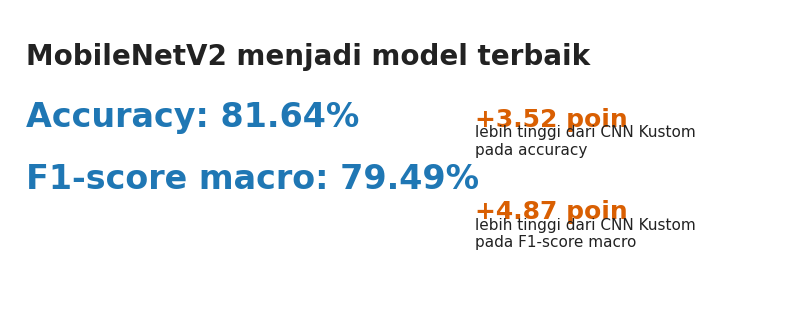

**Interpretasi:** MobileNetV2 adalah model terbaik karena memperoleh accuracy **81.64%** dan F1-score macro **79.49%**. Dibanding CNN Kustom, MobileNetV2 unggul **3.52 poin** pada accuracy dan **4.87 poin** pada F1-score macro.

In [4]:
best = comparison_df.sort_values("f1_macro", ascending=False).iloc[0]
baseline = comparison_df[comparison_df["model"] != best["model"]].iloc[0]

acc_gap = best["accuracy"] - baseline["accuracy"]
f1_gap = best["f1_macro"] - baseline["f1_macro"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis("off")

ax.text(0.02, 0.82, "MobileNetV2 menjadi model terbaik", fontsize=20, fontweight="bold", color=TEXT)
ax.text(0.02, 0.62, f"Accuracy: {percent(best['accuracy'])}", fontsize=24, fontweight="bold", color=PRIMARY)
ax.text(0.02, 0.42, f"F1-score macro: {percent(best['f1_macro'])}", fontsize=24, fontweight="bold", color=PRIMARY)

ax.text(0.60, 0.62, f"+{acc_gap * 100:.2f} poin", fontsize=18, fontweight="bold", color=ACCENT)
ax.text(0.60, 0.53, "lebih tinggi dari CNN Kustom\npada accuracy", fontsize=11, color=TEXT)

ax.text(0.60, 0.32, f"+{f1_gap * 100:.2f} poin", fontsize=18, fontweight="bold", color=ACCENT)
ax.text(0.60, 0.23, "lebih tinggi dari CNN Kustom\npada F1-score macro", fontsize=11, color=TEXT)

path = savefig("01_big_number_model_terbaik.png")
plt.show()

display(Markdown(
    f"**Interpretasi:** MobileNetV2 adalah model terbaik karena memperoleh "
    f"accuracy **{percent(best['accuracy'])}** dan F1-score macro **{percent(best['f1_macro'])}**. "
    f"Dibanding CNN Kustom, MobileNetV2 unggul **{acc_gap * 100:.2f} poin** pada accuracy "
    f"dan **{f1_gap * 100:.2f} poin** pada F1-score macro."
))

## 3. Tabel Perbandingan Model

**Pertanyaan yang dijawab:** seberapa besar perbedaan performa dua model pada semua metrik utama?

Tabel digunakan karena pembaca perlu melihat nilai detail secara presisi.

In [5]:
summary_table = comparison_df[[
    "model_label", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"
]].copy()
summary_table = summary_table.sort_values("f1_macro", ascending=False)

for col in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"]:
    summary_table[col] = (summary_table[col] * 100).round(2)

summary_table = summary_table.rename(columns={
    "model_label": "Model",
    "accuracy": "Accuracy (%)",
    "precision_macro": "Precision Macro (%)",
    "recall_macro": "Recall Macro (%)",
    "f1_macro": "F1 Macro (%)",
    "f1_weighted": "F1 Weighted (%)",
})

display(summary_table)

display(Markdown(
    "**Interpretasi:** MobileNetV2 berada di peringkat pertama pada seluruh metrik utama. "
    "Karena dataset memiliki jumlah data antar kelas yang tidak sepenuhnya seimbang, "
    "F1-score macro lebih informatif daripada accuracy saja."
))

,Model,Accuracy (%),Precision Macro (%),Recall Macro (%),F1 Macro (%),F1 Weighted (%)
0,MobileNetV2,81.64,80.94,79.20,79.49,82.02
1,CNN Kustom,78.12,76.42,74.77,74.62,77.81


**Interpretasi:** MobileNetV2 berada di peringkat pertama pada seluruh metrik utama. Karena dataset memiliki jumlah data antar kelas yang tidak sepenuhnya seimbang, F1-score macro lebih informatif daripada accuracy saja.

## 4. Dot Plot Metrik Utama

**Pertanyaan yang dijawab:** apakah keunggulan MobileNetV2 konsisten di berbagai metrik?

Dot plot dipilih karena hanya ada dua model dan beberapa metrik. Warna biru digunakan untuk model terbaik, sedangkan abu-abu untuk baseline.

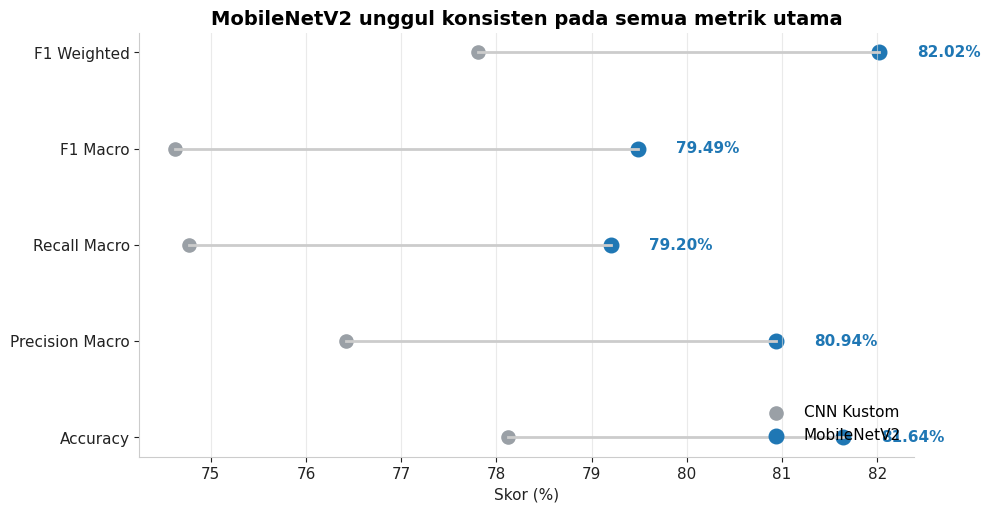

**Interpretasi:** Keunggulan MobileNetV2 tidak hanya terjadi pada accuracy, tetapi juga pada precision, recall, F1-score macro, dan F1-score weighted. Pola ini memperkuat kesimpulan bahwa MobileNetV2 lebih stabil sebagai model terbaik.

In [6]:
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"]
metric_labels = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision Macro",
    "recall_macro": "Recall Macro",
    "f1_macro": "F1 Macro",
    "f1_weighted": "F1 Weighted",
}

plot_df = comparison_df.melt(
    id_vars=["model", "model_label"],
    value_vars=metrics,
    var_name="metric",
    value_name="score"
)
plot_df["metric_label"] = plot_df["metric"].map(metric_labels)

fig, ax = plt.subplots(figsize=(10, 5.5))
y_positions = np.arange(len(metrics))

for i, metric in enumerate(metrics):
    subset = plot_df[plot_df["metric"] == metric]
    cnn = subset[subset["model"] == "custom_cnn"].iloc[0]
    mob = subset[subset["model"] == "mobilenetv2"].iloc[0]
    ax.plot([cnn["score"] * 100, mob["score"] * 100], [i, i], color="#cccccc", linewidth=2)
    ax.scatter(cnn["score"] * 100, i, color=BASELINE, s=90, label="CNN Kustom" if i == 0 else "")
    ax.scatter(mob["score"] * 100, i, color=PRIMARY, s=110, label="MobileNetV2" if i == 0 else "")
    ax.text(mob["score"] * 100 + 0.4, i, f"{mob['score'] * 100:.2f}%", va="center", color=PRIMARY, fontweight="bold")

ax.set_yticks(y_positions)
ax.set_yticklabels([metric_labels[m] for m in metrics])
ax.set_xlabel("Skor (%)")
ax.set_title("MobileNetV2 unggul konsisten pada semua metrik utama", fontsize=14, fontweight="bold")
ax.grid(axis="x", color=LIGHT_GRID, alpha=0.6)
ax.legend(loc="lower right", frameon=False)
path = savefig("02_dotplot_metrik_utama.png")
plt.show()

display(Markdown(
    "**Interpretasi:** Keunggulan MobileNetV2 tidak hanya terjadi pada accuracy, tetapi juga pada precision, recall, "
    "F1-score macro, dan F1-score weighted. Pola ini memperkuat kesimpulan bahwa MobileNetV2 lebih stabil sebagai model terbaik."
))

## 5. Performa per Kelas

**Pertanyaan yang dijawab:** kelas mana yang paling terbantu oleh MobileNetV2, dan kelas mana yang masih sulit?

Visual ini memakai F1-score karena F1-score menyeimbangkan precision dan recall.

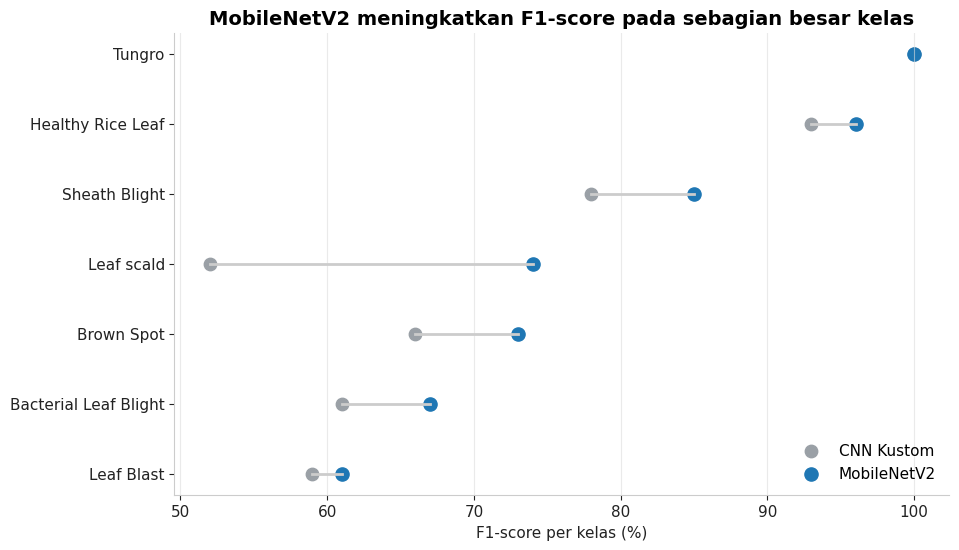

**Interpretasi:** MobileNetV2 memiliki F1-score lebih tinggi pada **6 dari 7 kelas**. Hal ini menunjukkan bahwa transfer learning membantu model mengenali pola penyakit daun padi pada sebagian besar kelas.

In [7]:
f1_pivot = class_metrics_df.pivot(index="class", columns="model", values="f1_score")
f1_pivot["gap_mobilenet_minus_cnn"] = f1_pivot["MobileNetV2"] - f1_pivot["CNN Kustom"]
f1_pivot = f1_pivot.sort_values("MobileNetV2")

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(f1_pivot))

for i, (_, row) in enumerate(f1_pivot.iterrows()):
    ax.plot([row["CNN Kustom"] * 100, row["MobileNetV2"] * 100], [i, i], color="#cccccc", linewidth=2)
    ax.scatter(row["CNN Kustom"] * 100, i, color=BASELINE, s=80, label="CNN Kustom" if i == 0 else "")
    ax.scatter(row["MobileNetV2"] * 100, i, color=PRIMARY, s=90, label="MobileNetV2" if i == 0 else "")

ax.set_yticks(y)
ax.set_yticklabels(f1_pivot.index)
ax.set_xlabel("F1-score per kelas (%)")
ax.set_title("MobileNetV2 meningkatkan F1-score pada sebagian besar kelas", fontsize=14, fontweight="bold")
ax.grid(axis="x", color=LIGHT_GRID, alpha=0.6)
ax.legend(loc="lower right", frameon=False)
path = savefig("03_f1_per_kelas_slope.png")
plt.show()

improved_count = (f1_pivot["gap_mobilenet_minus_cnn"] > 0).sum()
total_classes = len(f1_pivot)
display(Markdown(
    f"**Interpretasi:** MobileNetV2 memiliki F1-score lebih tinggi pada **{improved_count} dari {total_classes} kelas**. "
    "Hal ini menunjukkan bahwa transfer learning membantu model mengenali pola penyakit daun padi pada sebagian besar kelas."
))

## 6. Kelas dengan Peningkatan dan Penurunan Terbesar

**Pertanyaan yang dijawab:** peningkatan MobileNetV2 paling terlihat pada kelas apa?

Tabel kecil dipakai karena angka detail lebih mudah dibaca dalam bentuk tabel daripada grafik yang terlalu ramai.

In [8]:
gap_table = f1_pivot[["CNN Kustom", "MobileNetV2", "gap_mobilenet_minus_cnn"]].copy()
gap_table = gap_table.sort_values("gap_mobilenet_minus_cnn", ascending=False)
gap_table_display = (gap_table * 100).round(2).rename(columns={
    "CNN Kustom": "F1 CNN Kustom (%)",
    "MobileNetV2": "F1 MobileNetV2 (%)",
    "gap_mobilenet_minus_cnn": "Selisih MobileNetV2 - CNN (%)",
})

display(gap_table_display)

best_gain = gap_table.index[0]
worst_gain = gap_table.index[-1]
display(Markdown(
    f"**Interpretasi:** Peningkatan terbesar MobileNetV2 terjadi pada kelas **{best_gain}**. "
    f"Kelas yang masih perlu diperhatikan adalah **{worst_gain}**, karena MobileNetV2 tidak memberi peningkatan terbesar pada kelas tersebut."
))

model,F1 CNN Kustom (%),F1 MobileNetV2 (%),Selisih MobileNetV2 - CNN (%)
class,,,
Leaf scald,52.0,74.0,22.0
Brown Spot,66.0,73.0,7.0
Sheath Blight,78.0,85.0,7.0
Bacterial Leaf Blight,61.0,67.0,6.0
Healthy Rice Leaf,93.0,96.0,3.0
Leaf Blast,59.0,61.0,2.0
Tungro,100.0,100.0,0.0


**Interpretasi:** Peningkatan terbesar MobileNetV2 terjadi pada kelas **Leaf scald**. Kelas yang masih perlu diperhatikan adalah **Tungro**, karena MobileNetV2 tidak memberi peningkatan terbesar pada kelas tersebut.

## 7. Support per Kelas

**Pertanyaan yang dijawab:** apakah jumlah data test antar kelas seimbang?

Support perlu ditampilkan karena metrik accuracy dapat dipengaruhi oleh kelas yang jumlah datanya lebih besar.

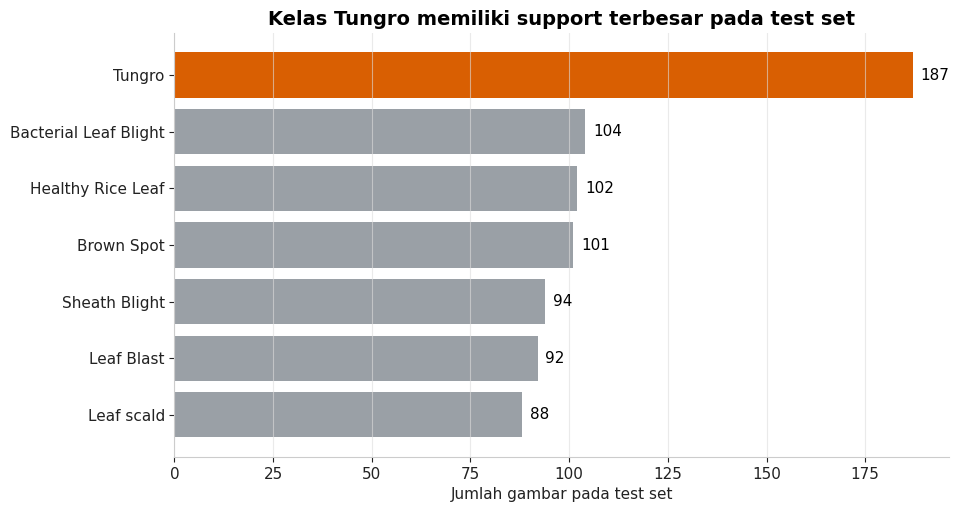

**Interpretasi:** Kelas Tungro memiliki jumlah data test terbesar. Karena distribusi kelas tidak sepenuhnya seimbang, F1-score macro digunakan agar setiap kelas memiliki kontribusi yang lebih adil dalam evaluasi.

In [9]:
support_df = custom_class_df[["class", "support"]].sort_values("support")

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [ACCENT if cls == support_df.iloc[-1]["class"] else BASELINE for cls in support_df["class"]]
ax.barh(support_df["class"], support_df["support"], color=colors)
ax.set_xlabel("Jumlah gambar pada test set")
ax.set_title("Kelas Tungro memiliki support terbesar pada test set", fontsize=14, fontweight="bold")
ax.grid(axis="x", color=LIGHT_GRID, alpha=0.6)

for i, value in enumerate(support_df["support"]):
    ax.text(value + 2, i, str(value), va="center")

path = savefig("04_support_per_kelas.png")
plt.show()

display(Markdown(
    "**Interpretasi:** Kelas Tungro memiliki jumlah data test terbesar. Karena distribusi kelas tidak sepenuhnya seimbang, "
    "F1-score macro digunakan agar setiap kelas memiliki kontribusi yang lebih adil dalam evaluasi."
))

## 8. Confusion Matrix CNN Kustom

**Pertanyaan yang dijawab:** pola kesalahan apa yang muncul pada CNN Kustom?

Confusion matrix cocok digunakan karena hasil klasifikasi multikelas perlu dilihat dari hubungan antara label asli dan prediksi.

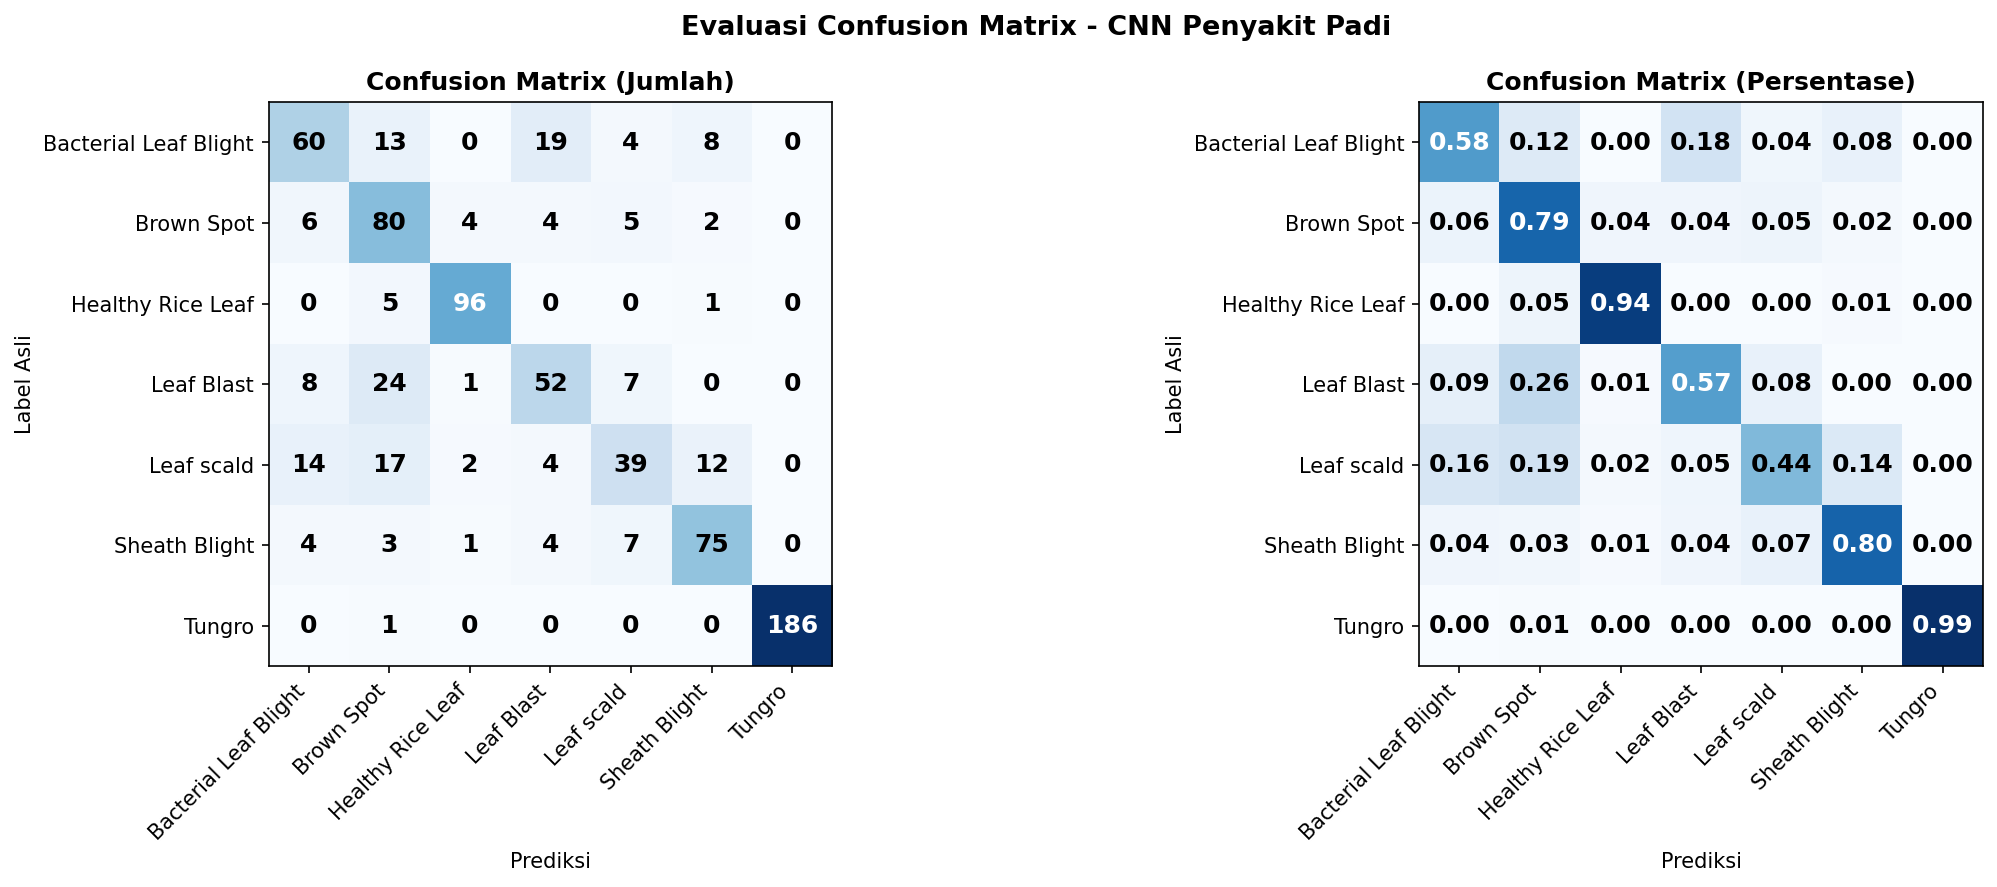

**Interpretasi:** Confusion matrix CNN Kustom membantu melihat kelas mana yang sering tertukar. Baca diagonal sebagai prediksi benar; nilai di luar diagonal menunjukkan kesalahan klasifikasi. Kelas dengan F1-score lebih rendah, seperti Leaf scald atau Leaf Blast, perlu diperiksa pada bagian luar diagonal.

In [10]:
custom_cm_path = REPORT_DIR / "confusion_matrix_custom_cnn.png"
display(Image(filename=str(custom_cm_path)))

display(Markdown(
    "**Interpretasi:** Confusion matrix CNN Kustom membantu melihat kelas mana yang sering tertukar. "
    "Baca diagonal sebagai prediksi benar; nilai di luar diagonal menunjukkan kesalahan klasifikasi. "
    "Kelas dengan F1-score lebih rendah, seperti Leaf scald atau Leaf Blast, perlu diperiksa pada bagian luar diagonal."
))

## 9. Confusion Matrix MobileNetV2

**Pertanyaan yang dijawab:** apakah MobileNetV2 mengurangi kesalahan klasifikasi dibanding CNN Kustom?

Visual ini perlu dibaca bersama classification report agar tidak hanya melihat jumlah benar, tetapi juga distribusi kesalahan antar kelas.

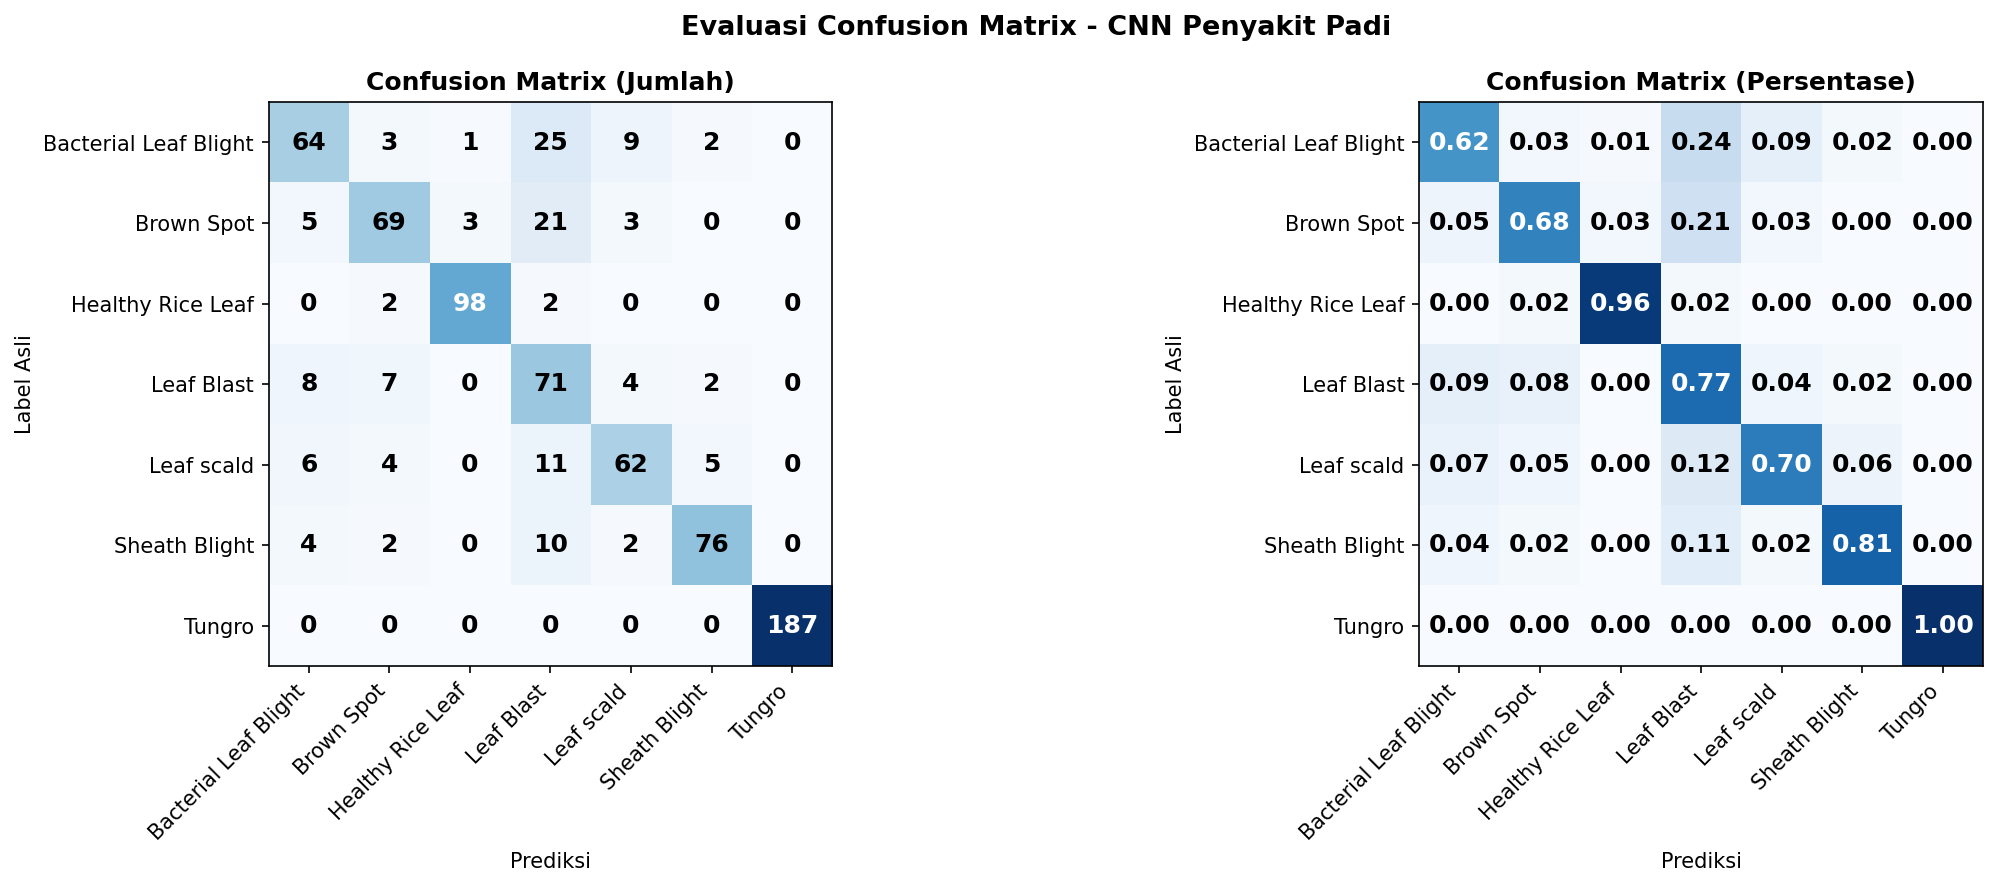

**Interpretasi:** MobileNetV2 menghasilkan skor keseluruhan yang lebih tinggi. Confusion matrix ini digunakan untuk memastikan bahwa peningkatan performa tidak hanya berasal dari satu kelas dominan, tetapi juga terlihat pada pola klasifikasi beberapa kelas penyakit.

In [11]:
mobilenet_cm_path = REPORT_DIR / "confusion_matrix_mobilenetv2.png"
display(Image(filename=str(mobilenet_cm_path)))

display(Markdown(
    "**Interpretasi:** MobileNetV2 menghasilkan skor keseluruhan yang lebih tinggi. "
    "Confusion matrix ini digunakan untuk memastikan bahwa peningkatan performa tidak hanya berasal dari satu kelas dominan, "
    "tetapi juga terlihat pada pola klasifikasi beberapa kelas penyakit."
))

## 10. Grafik Training

**Pertanyaan yang dijawab:** bagaimana perilaku training dan validation selama 20 epoch?

Grafik training digunakan untuk membaca indikasi overfitting atau kestabilan proses pelatihan.

### Grafik Training CNN Kustom

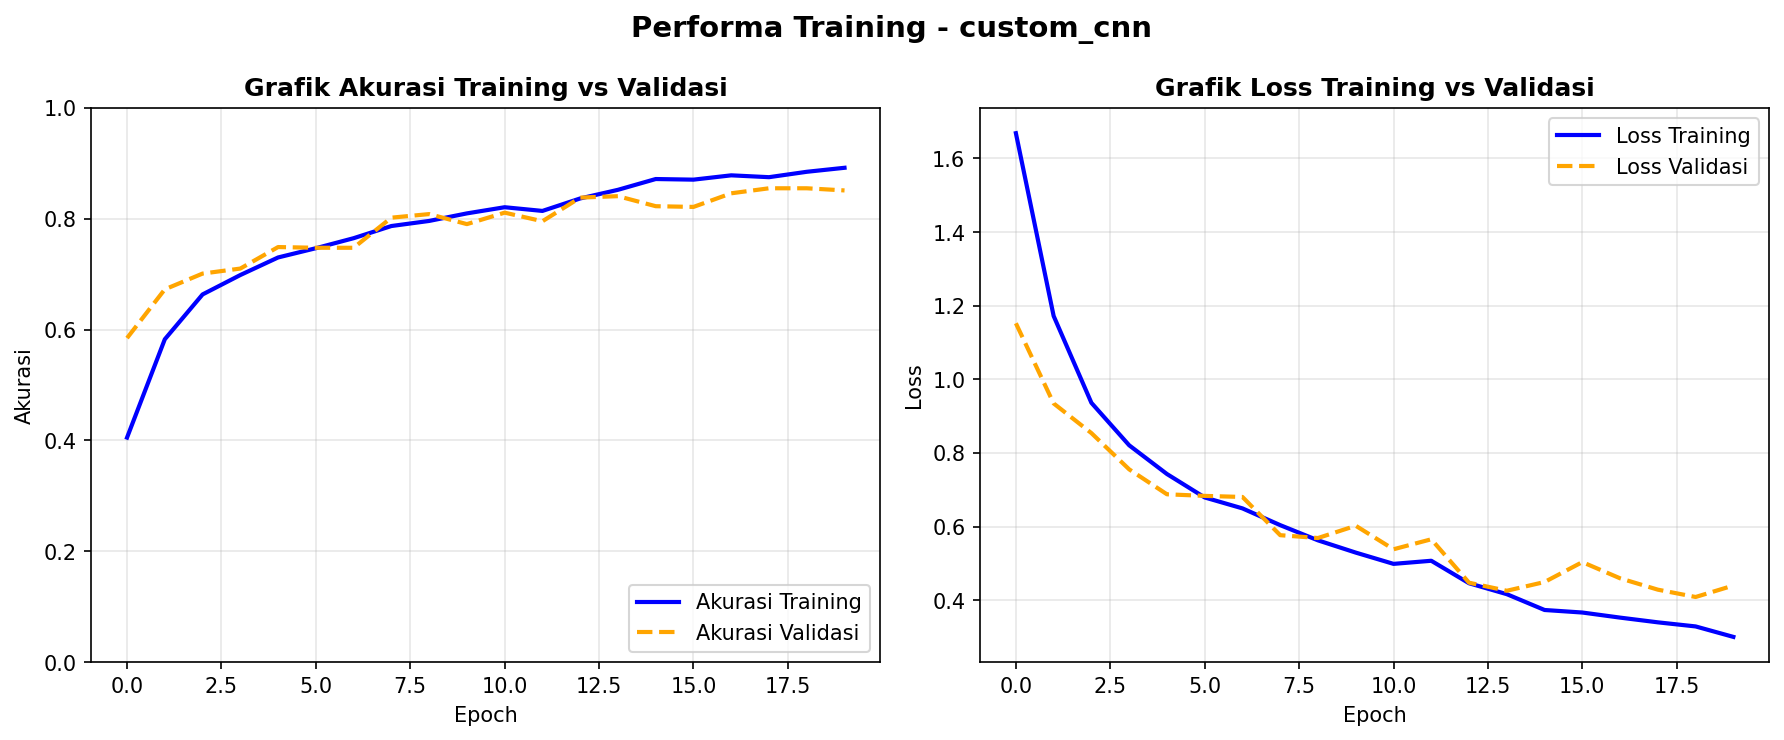

### Grafik Training MobileNetV2

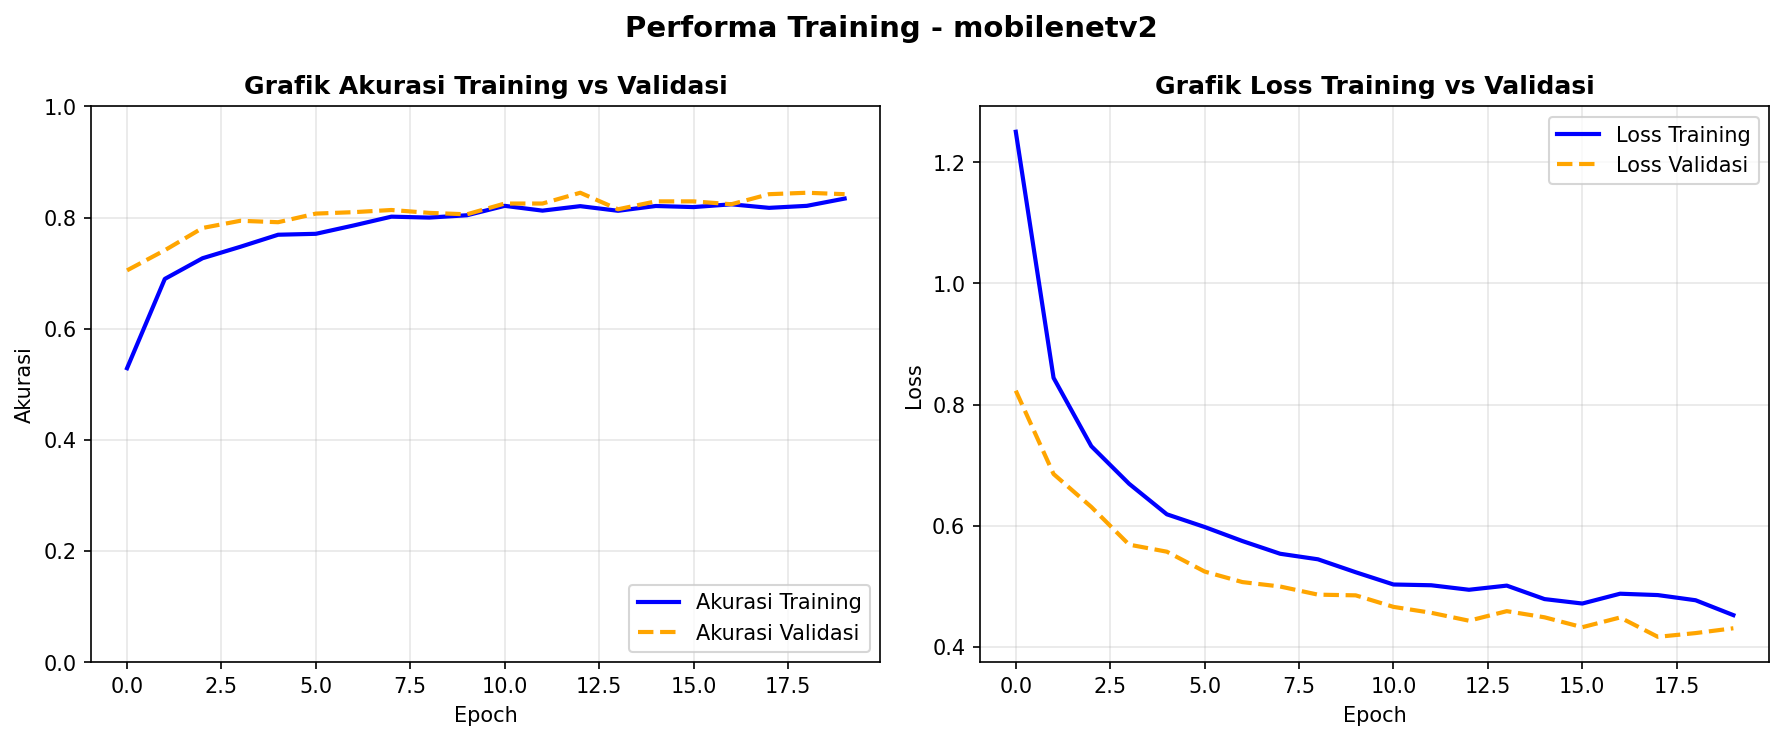

**Interpretasi:** Grafik training dan validation perlu dibaca untuk melihat apakah model belajar secara stabil. Jika training accuracy meningkat tetapi validation accuracy stagnan atau turun, hal tersebut dapat menjadi indikasi overfitting. Dalam laporan, grafik ini sebaiknya digunakan sebagai pendukung pembahasan, bukan satu-satunya dasar kesimpulan.

In [12]:
display(Markdown("### Grafik Training CNN Kustom"))
display(Image(filename=str(REPORT_DIR / "grafik_pelatihan_custom_cnn.png")))

display(Markdown("### Grafik Training MobileNetV2"))
display(Image(filename=str(REPORT_DIR / "grafik_pelatihan_mobilenetv2.png")))

display(Markdown(
    "**Interpretasi:** Grafik training dan validation perlu dibaca untuk melihat apakah model belajar secara stabil. "
    "Jika training accuracy meningkat tetapi validation accuracy stagnan atau turun, hal tersebut dapat menjadi indikasi overfitting. "
    "Dalam laporan, grafik ini sebaiknya digunakan sebagai pendukung pembahasan, bukan satu-satunya dasar kesimpulan."
))

## 11. Ringkasan Cerita untuk BAB IV

Bagian ini merangkum narasi hasil yang dapat langsung dipakai untuk BAB IV atau paper.

In [13]:
story = f"""
### Ringkasan Narasi

Eksperimen membandingkan CNN Kustom dan MobileNetV2 pada tujuh kondisi daun padi. 
Berdasarkan hasil pengujian pada test set, MobileNetV2 memperoleh accuracy **{percent(best['accuracy'])}** 
dan F1-score macro **{percent(best['f1_macro'])}**. CNN Kustom memperoleh accuracy **{percent(baseline['accuracy'])}** 
dan F1-score macro **{percent(baseline['f1_macro'])}**.

Keunggulan MobileNetV2 menunjukkan bahwa transfer learning membantu model mengenali pola visual penyakit daun padi 
secara lebih baik dibandingkan CNN Kustom yang dilatih dari awal. Namun, CNN Kustom tetap penting sebagai baseline 
karena menunjukkan performa yang cukup baik tanpa pretrained weights.

Kesimpulan utama: **MobileNetV2 adalah model terbaik pada eksperimen ini**, terutama karena unggul pada accuracy dan F1-score macro.
"""

display(Markdown(story))


### Ringkasan Narasi

Eksperimen membandingkan CNN Kustom dan MobileNetV2 pada tujuh kondisi daun padi. 
Berdasarkan hasil pengujian pada test set, MobileNetV2 memperoleh accuracy **81.64%** 
dan F1-score macro **79.49%**. CNN Kustom memperoleh accuracy **78.12%** 
dan F1-score macro **74.62%**.

Keunggulan MobileNetV2 menunjukkan bahwa transfer learning membantu model mengenali pola visual penyakit daun padi 
secara lebih baik dibandingkan CNN Kustom yang dilatih dari awal. Namun, CNN Kustom tetap penting sebagai baseline 
karena menunjukkan performa yang cukup baik tanpa pretrained weights.

Kesimpulan utama: **MobileNetV2 adalah model terbaik pada eksperimen ini**, terutama karena unggul pada accuracy dan F1-score macro.


## 12. Checklist Storytelling with Data

Checklist berikut digunakan untuk memastikan visualisasi tetap fokus pada pesan penelitian:

- Setiap grafik punya pertanyaan yang dijawab.
- Judul grafik menyampaikan insight.
- Warna biru hanya digunakan untuk highlight MobileNetV2.
- CNN Kustom digunakan sebagai baseline abu-abu.
- Angka panjang dibulatkan menjadi persen dua desimal.
- Grafik tidak memakai 3D, pie chart, atau terlalu banyak warna.
- Confusion matrix digunakan untuk membaca pola kesalahan, bukan hanya hiasan.
- Kesimpulan tidak mengklaim berlebihan: MobileNetV2 lebih baik pada dataset dan skenario eksperimen ini.